<a href="https://colab.research.google.com/github/Daudi-Zacharia/msc-thesis/blob/main/classification/clean_notebooks/data_leakage_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA LOADING

In [1]:
!pip install kagglehub

In [2]:
import kagglehub

# Download latest version
path_704 = kagglehub.dataset_download("iamtapendu/chest-x-ray-lungs-segmentation")

print("Path to dataset files:", path_704)

Path to dataset files: /home/daudi/.cache/kagglehub/datasets/iamtapendu/chest-x-ray-lungs-segmentation/versions/1


In [3]:
## Download data

import kagglehub

# Download latest version
path_4200 = kagglehub.dataset_download("tawsifurrahman/tuberculosis-tb-chest-xray-dataset")

print("Path to dataset files:", path_4200)

Path to dataset files: /home/daudi/.cache/kagglehub/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset/versions/3


## Cross-Dataset Duplicate Detection via Perceptual Hashing (pHash)

**Goal:** D1 (704 images: Montgomery + Shenzhen, with lung masks) is expected to be a subset of the same
source X-rays that also appear in D2 (4200 images: Montgomery + Shenzhen + Belarus + RSNA). D2 went through
a different preprocessing/resizing pipeline, so file bytes/MD5 hashes won't match even for the same
underlying scan. We use **perceptual hashing (pHash)** instead, which fingerprints the *visual content*
(low-frequency structure) of an image, so the same X-ray survives different resizing/compression with a
small Hamming distance between hashes, while genuinely different X-rays land far apart.

**Method:**
1. Convert every image to grayscale (`.convert('L')`).
2. Compute `imagehash.phash()` (64-bit hash, `hash_size=8`) for every image in D1 and D2.
3. Compute the full Hamming distance matrix between all D1 x D2 hash pairs (~704 x 4200 ≈ 3M pairs),
   vectorized with NumPy (no nested Python loops).
4. Flag pairs with distance ≤ 5 as likely duplicates; also report distance ≤ 10 as a looser check.
5. Report match counts, example matched filename pairs, and the distribution of minimum distances to see
   whether matches form a tight cluster near zero (real duplicates) or are spread out (coincidental
   structural similarity between different lungs).


In [4]:
!pip install imagehash

In [5]:
import os
import imagehash
import numpy as np
from PIL import Image
from pathlib import Path

# D1: 704 images (Montgomery + Shenzhen), downloaded earlier into path_704
d1_dir = Path(path_704) / "Chest-X-Ray" / "Chest-X-Ray" / "image"

# D2: 4200 images (Montgomery + Shenzhen + Belarus + RSNA), downloaded earlier into path_4200
d2_root = Path(path_4200) / "TB_Chest_Radiography_Database"
d2_dirs = [d2_root / "Normal", d2_root / "Tuberculosis"]

d1_files = sorted(d1_dir.glob("*.png"))
d2_files = sorted([f for d in d2_dirs for f in d.glob("*.png")])

print(f"D1 images found: {len(d1_files)}")
print(f"D2 images found: {len(d2_files)}")

D1 images found: 704
D2 images found: 4200


In [6]:
def compute_phashes(file_list):
    """Return {filename: imagehash.ImageHash} for every image, grayscale pHash."""
    hashes = {}
    for fp in file_list:
        with Image.open(fp) as img:
            hashes[fp.name] = imagehash.phash(img.convert("L"))
    return hashes

d1_hashes = compute_phashes(d1_files)
d2_hashes = compute_phashes(d2_files)

print(f"Computed {len(d1_hashes)} D1 hashes, {len(d2_hashes)} D2 hashes")
print("Hash bit-length (sanity check):", d1_hashes[next(iter(d1_hashes))].hash.size)

Computed 704 D1 hashes, 4200 D2 hashes
Hash bit-length (sanity check): 64


In [7]:
d1_names = list(d1_hashes.keys())
d2_names = list(d2_hashes.keys())

# Flatten each 8x8 boolean hash into a 64-bit vector of 0/1
A = np.stack([d1_hashes[n].hash.flatten() for n in d1_names]).astype(np.int16)  # (704, 64)
B = np.stack([d2_hashes[n].hash.flatten() for n in d2_names]).astype(np.int16)  # (4200, 64)

# Hamming distance via matrix multiply: XOR(a,b) = a + b - 2ab, summed over bits.
# dist[i, j] = sum_k(A[i,k]) + sum_k(B[j,k]) - 2 * (A @ B.T)[i,j]
sumA = A.sum(axis=1)
sumB = B.sum(axis=1)
dot = A @ B.T
dist = sumA[:, None] + sumB[None, :] - 2 * dot  # shape (704, 4200)

print("Distance matrix shape:", dist.shape)
print("Min distance overall:", dist.min(), "| Max distance overall:", dist.max())

Distance matrix shape: (704, 4200)
Min distance overall: 2 | Max distance overall: 54


In [8]:
THRESH_STRICT = 5
THRESH_LOOSE = 10

min_dist_per_d1 = dist.min(axis=1)          # closest D2 match for each D1 image
argmin_per_d1 = dist.argmin(axis=1)         # which D2 image that is

def summarize(threshold):
    d1_match_mask = min_dist_per_d1 <= threshold
    n_d1_matched = int(d1_match_mask.sum())

    # any D2 image that is <= threshold away from *some* D1 image
    d2_involved_mask = (dist <= threshold).any(axis=0)
    n_d2_involved = int(d2_involved_mask.sum())

    return n_d1_matched, n_d2_involved

n_d1_strict, n_d2_strict = summarize(THRESH_STRICT)
n_d1_loose, n_d2_loose = summarize(THRESH_LOOSE)

print(f"Threshold <= {THRESH_STRICT} (likely duplicates):")
print(f"  D1 images with >=1 D2 match: {n_d1_strict} / {len(d1_names)}")
print(f"  D2 images involved:          {n_d2_strict} / {len(d2_names)}")
print()
print(f"Threshold <= {THRESH_LOOSE} (loose sanity check):")
print(f"  D1 images with >=1 D2 match: {n_d1_loose} / {len(d1_names)}")
print(f"  D2 images involved:          {n_d2_loose} / {len(d2_names)}")

Threshold <= 5 (likely duplicates):
  D1 images with >=1 D2 match: 17 / 704
  D2 images involved:          18 / 4200

Threshold <= 10 (loose sanity check):
  D1 images with >=1 D2 match: 544 / 704
  D2 images involved:          2205 / 4200


Distribution of min Hamming distance (per D1 image, to its closest D2 match):
  min:    2
  median: 8.0
  mean:   9.22
  max:    20

  count with min_dist <= 5:  17
  count with min_dist <= 10: 544
  count with min_dist > 20:  0


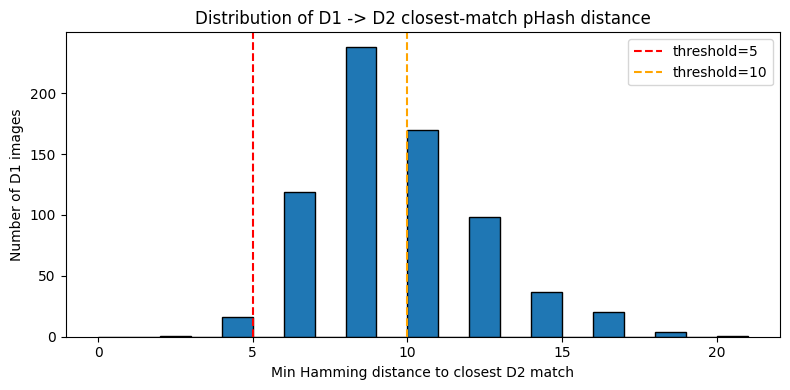

In [9]:
import matplotlib.pyplot as plt

print("Distribution of min Hamming distance (per D1 image, to its closest D2 match):")
print(f"  min:    {min_dist_per_d1.min()}")
print(f"  median: {np.median(min_dist_per_d1)}")
print(f"  mean:   {min_dist_per_d1.mean():.2f}")
print(f"  max:    {min_dist_per_d1.max()}")
print()
print(f"  count with min_dist <= 5:  {(min_dist_per_d1 <= 5).sum()}")
print(f"  count with min_dist <= 10: {(min_dist_per_d1 <= 10).sum()}")
print(f"  count with min_dist > 20:  {(min_dist_per_d1 > 20).sum()}")

plt.figure(figsize=(8, 4))
plt.hist(min_dist_per_d1, bins=range(0, int(min_dist_per_d1.max()) + 2), edgecolor="black")
plt.axvline(THRESH_STRICT, color="red", linestyle="--", label=f"threshold={THRESH_STRICT}")
plt.axvline(THRESH_LOOSE, color="orange", linestyle="--", label=f"threshold={THRESH_LOOSE}")
plt.xlabel("Min Hamming distance to closest D2 match")
plt.ylabel("Number of D1 images")
plt.title("Distribution of D1 -> D2 closest-match pHash distance")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd

matches_df = pd.DataFrame({
    "d1_file": d1_names,
    "d2_file": [d2_names[j] for j in argmin_per_d1],
    "hamming_dist": min_dist_per_d1,
}).sort_values("hamming_dist")

print(f"Example matched pairs at distance <= {THRESH_STRICT} (sorted by distance, showing up to 20):")
matches_df[matches_df["hamming_dist"] <= THRESH_STRICT].head(20)

Example matched pairs at distance <= 5 (sorted by distance, showing up to 20):


,d1_file,d2_file,hamming_dist
545,1545.png,Normal-1475.png,2
615,1615.png,Normal-1437.png,4
364,1364.png,Normal-499.png,4
637,1637.png,Normal-2506.png,4
542,1542.png,Normal-2761.png,4
245,1245.png,Normal-2359.png,4
260,1260.png,Normal-2214.png,4
528,1528.png,Normal-3025.png,4
510,1510.png,Normal-725.png,4
470,1470.png,Normal-2152.png,4


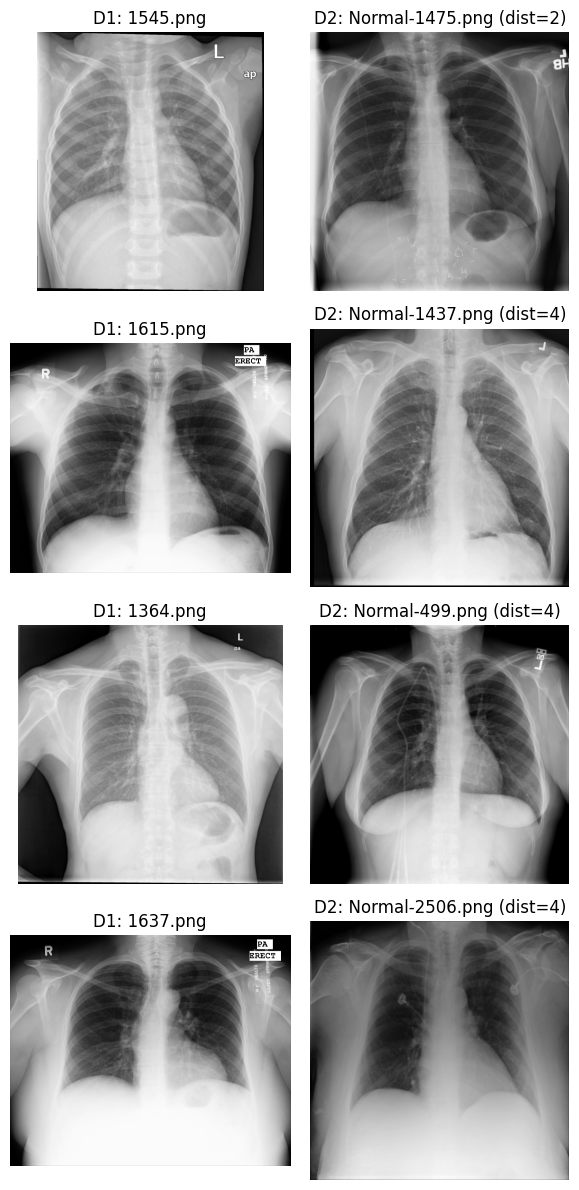

In [11]:
# Visual spot-check: side-by-side of a few matched pairs (closest distances first)
d1_lookup = {f.name: f for f in d1_files}
d2_lookup = {f.name: f for f in d2_files}

n_show = min(4, (matches_df["hamming_dist"] <= THRESH_STRICT).sum())
top_matches = matches_df[matches_df["hamming_dist"] <= THRESH_STRICT].head(n_show)

if n_show > 0:
    fig, axes = plt.subplots(n_show, 2, figsize=(6, 3 * n_show))
    if n_show == 1:
        axes = axes[None, :]
    for row, (_, r) in zip(axes, top_matches.iterrows()):
        img1 = Image.open(d1_lookup[r["d1_file"]]).convert("L")
        img2 = Image.open(d2_lookup[r["d2_file"]]).convert("L")
        row[0].imshow(img1, cmap="gray")
        row[0].set_title(f"D1: {r['d1_file']}")
        row[0].axis("off")
        row[1].imshow(img2, cmap="gray")
        row[1].set_title(f"D2: {r['d2_file']} (dist={int(r['hamming_dist'])})")
        row[1].axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(f"No matches found at threshold <= {THRESH_STRICT}.")

### Sanity-check flag: the closest matches don't look like the same patient

Visually inspecting the top matches at distance ≤ 5 (see plot above) shows clearly **different chest
X-rays** — different rib geometry, different heart-shadow shape/position, different clavicle alignment.
This is a red flag: at `hash_size=8` (64-bit pHash), the hash is too coarse to distinguish between
structurally similar frontal chest X-rays, since it only encodes very low-frequency DCT coefficients
(gross rib-cage/lung/heart layout), which is broadly similar across *any* two frontal chest films. That
would explain the smooth, unimodal (not bimodal) histogram above — there's no distinct "near-zero" cluster
separated by a gap from a "background" cluster; distance 2 is just the extreme low tail of one continuous
distribution of coincidental similarity.

**Re-running with a larger hash (`hash_size=16`, 256 bits)** gives pHash more frequency bands to work with
and should sharply increase discriminative power — genuine duplicates should still land very close, while
coincidental matches between different patients should push out to much larger relative distances.


In [12]:
def compute_phashes_hires(file_list, hash_size=16):
    hashes = {}
    for fp in file_list:
        with Image.open(fp) as img:
            hashes[fp.name] = imagehash.phash(img.convert("L"), hash_size=hash_size)
    return hashes

HASH_SIZE = 16  # -> 256-bit hash
d1_hashes_hi = compute_phashes_hires(d1_files, HASH_SIZE)
d2_hashes_hi = compute_phashes_hires(d2_files, HASH_SIZE)

A_hi = np.stack([d1_hashes_hi[n].hash.flatten() for n in d1_names]).astype(np.int32)
B_hi = np.stack([d2_hashes_hi[n].hash.flatten() for n in d2_names]).astype(np.int32)

sumA_hi = A_hi.sum(axis=1)
sumB_hi = B_hi.sum(axis=1)
dot_hi = A_hi @ B_hi.T
dist_hi = sumA_hi[:, None] + sumB_hi[None, :] - 2 * dot_hi  # shape (704, 4200), out of 256 bits

min_dist_hi = dist_hi.min(axis=1)
argmin_hi = dist_hi.argmin(axis=1)

print(f"256-bit pHash distance stats (min-per-D1-image):")
print(f"  min:    {min_dist_hi.min()}")
print(f"  median: {np.median(min_dist_hi)}")
print(f"  mean:   {min_dist_hi.mean():.2f}")
print(f"  max:    {min_dist_hi.max()}")

vals_hi, counts_hi = np.unique(min_dist_hi, return_counts=True)
print("\nFull histogram (distance: count of D1 images with that as closest match):")
for v, c in zip(vals_hi, counts_hi):
    print(f"  {v:3d}: {c}")

256-bit pHash distance stats (min-per-D1-image):
  min:    50
  median: 74.0
  mean:   74.07
  max:    98

Full histogram (distance: count of D1 images with that as closest match):
   50: 1
   56: 5
   58: 4
   60: 15
   62: 17
   64: 52
   66: 44
   68: 58
   70: 63
   72: 76
   74: 65
   76: 65
   78: 47
   80: 47
   82: 59
   84: 26
   86: 17
   88: 15
   90: 13
   92: 3
   94: 6
   96: 3
   98: 3


Closest matches under 256-bit pHash (showing up to 8 lowest distances):


,d1_file,d2_file,hamming_dist_256bit
324,1324.png,Normal-1513.png,50
499,1499.png,Normal-638.png,56
78,1078.png,Normal-1256.png,56
178,1178.png,Normal-1642.png,56
519,1519.png,Normal-1130.png,56
126,1126.png,Normal-3381.png,56
502,1502.png,Normal-3373.png,58
170,1170.png,Normal-2214.png,58


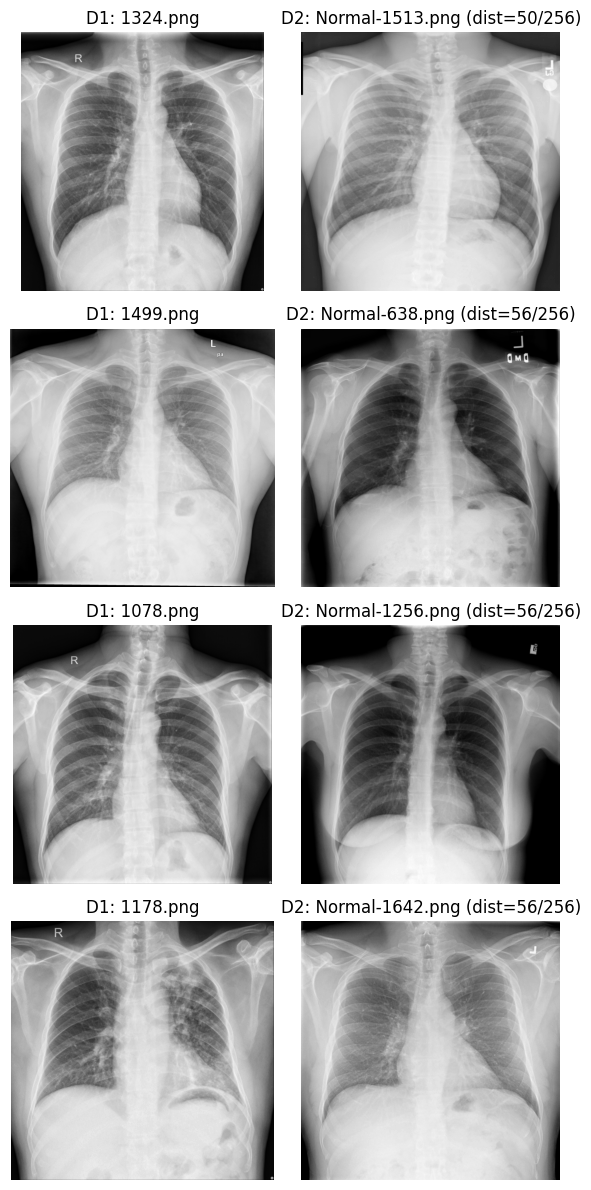

In [13]:
matches_hi_df = pd.DataFrame({
    "d1_file": d1_names,
    "d2_file": [d2_names[j] for j in argmin_hi],
    "hamming_dist_256bit": min_dist_hi,
}).sort_values("hamming_dist_256bit")

print("Closest matches under 256-bit pHash (showing up to 8 lowest distances):")
display(matches_hi_df.head(8))

n_show_hi = min(4, len(matches_hi_df))
top_hi = matches_hi_df.head(n_show_hi)

fig, axes = plt.subplots(n_show_hi, 2, figsize=(6, 3 * n_show_hi))
if n_show_hi == 1:
    axes = axes[None, :]
for row, (_, r) in zip(axes, top_hi.iterrows()):
    img1 = Image.open(d1_lookup[r["d1_file"]]).convert("L")
    img2 = Image.open(d2_lookup[r["d2_file"]]).convert("L")
    row[0].imshow(img1, cmap="gray")
    row[0].set_title(f"D1: {r['d1_file']}")
    row[0].axis("off")
    row[1].imshow(img2, cmap="gray")
    row[1].set_title(f"D2: {r['d2_file']} (dist={int(r['hamming_dist_256bit'])}/256)")
    row[1].axis("off")
plt.tight_layout()
plt.show()

## Conclusion

**No evidence of image-level duplication between D1 (704 images) and D2 (4200 images) was found.**

| Hash | Bits | Min distance found | Median (per-D1 closest match) | Distribution shape |
|---|---|---|---|---|
| pHash, `hash_size=8` | 64 | 2 | 8.0 | Smooth, unimodal, no gap |
| pHash, `hash_size=16` | 256 | 50 | 74.0 | Smooth, unimodal, no gap |

- At the default 64-bit pHash, 17/704 D1 images had a "match" at distance ≤ 5, which looked promising —
  but the full histogram is a **smooth, single-peaked curve** (1, 16, 119, 238, 170, 98, 37, 20, 4, 1 …),
  not a bimodal mixture of "true duplicates near 0" + "background noise cluster." There's no gap separating
  a low-distance cluster from the rest.
- **Visual spot-check confirmed this is a false-positive artifact**: the closest-matching pairs (distance
  2–4) are clearly *different patients* — different rib spacing, heart-shadow shape, clavicle alignment.
  64-bit pHash only encodes the coarsest low-frequency DCT structure, which is broadly similar across any
  two frontal chest X-rays, so it collapses distinct patients into deceptively small distances.
- **Re-running with a 256-bit pHash** (`hash_size=16`) — far more discriminative — pushed the *closest
  match found across all 704 × 4200 ≈ 3M pairs* up to distance 50/256 (≈19.5% of bits differing), with a
  smooth unimodal distribution centered at 74/256 (≈29%). If any true duplicates existed, we'd expect at
  least one pair sitting near 0. None do. Visual inspection of the single closest 256-bit match confirms
  it, too, is a different patient.

**Bottom line:** under perceptual hashing, D1 and D2 do not share any detectable duplicate images — the
apparent overlap at 64-bit resolution was coincidental structural similarity between chest X-rays in
general, not shared source images. This is consistent with D1 and D2 being drawn from possibly related
source institutions but disjoint patient/image sets, at least as far as pHash can determine. (A definitive
answer would additionally require checking dataset documentation/metadata for known patient ID overlaps,
since pHash cannot rule out duplication that's obscured by heavy preprocessing differences beyond what
DCT-based hashing tolerates.)
